# 09 · Feature roles, whitelists and frozen folds

Turns the EDA into modelling rules: which columns may predict what, how structural expectations, provenance and cross-component features are built, and the validation folds. Vulnerability, rurality and hazard variables are audit-only and saved separately. USFS and CarbonPlan building counts are excluded. Eastern Washington is not scored in the competition and is kept as an academic transfer set.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Feature roles
Every column gets exactly one role, so nothing leaks between stages. The main **expectation model** (what a tract *should* contain given its structure) may use only structural features. Everything about vulnerability, rurality and hazards is **audit-only** and is applied after the risk scores are frozen. Observed map counts are the *outcomes* being compared with their expectation.

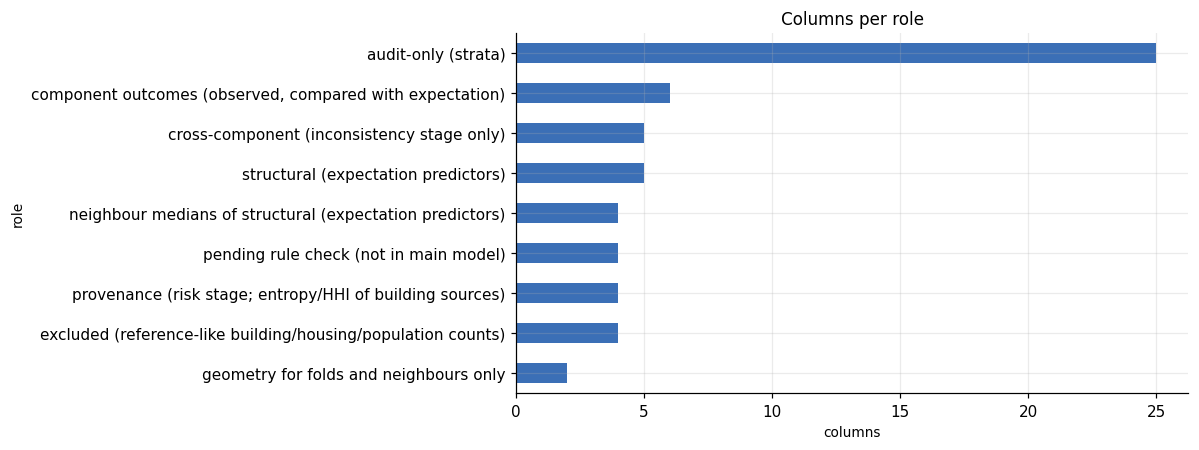

role
audit-only (strata)                                             ur_class, rural, ruca_primary, rucc_2023, trib...
component outcomes (observed, compared with expectation)        bldg_n, road_km_hwy, poi_n, poi_n_fire, poi_n_...
cross-component (inconsistency stage only)                      bldg_per_hu, poi_per_100_bldg, poi_per_1k_pop,...
excluded (reference-like building/housing/population counts)    usfs_BuildingCount_sum, usfs_HUCount_sum, usfs...
geometry for folds and neighbours only                                                         INTPTLAT, INTPTLON
neighbour medians of structural (expectation predictors)        nb_land_km2, nb_housing_units, nb_pop_density,...
pending rule check (not in main model)                            share_msft, share_osm, share_esri, share_google
provenance (risk stage; entropy/HHI of building sources)               src_entropy, src_hhi, src_n, src_top_share
structural (expectation predictors)                             land_km2, housing_u

In [2]:
from scipy.special import xlogy
REGS_COMP = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx"]       # scored in the competition; Eastern WA is an academic transfer set
df["competition"] = df.region.isin(REGS_COMP); df["hu_per_km2"] = df.housing_units / df.land_km2.replace(0, np.nan)
roles = {
 "structural (expectation predictors)": ["land_km2", "housing_units", "pop_total", "hu_per_km2", "pop_density"],
 "neighbour medians of structural (expectation predictors)": ["nb_land_km2", "nb_housing_units", "nb_pop_density", "nb_hu_per_km2"],
 "component outcomes (observed, compared with expectation)": ["bldg_n", "road_km_hwy", "poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school"],
 "provenance (risk stage; entropy/HHI of building sources)": ["src_entropy", "src_hhi", "src_n", "src_top_share"],
 "cross-component (inconsistency stage only)": ["bldg_per_hu", "poi_per_100_bldg", "poi_per_1k_pop", "road_per_bldg", "fire_per_10k_pop"],
 "pending rule check (not in main model)": ["share_msft", "share_osm", "share_esri", "share_google"],
 "audit-only (strata)": ["ur_class", "rural", "ruca_primary", "rucc_2023", "tribal", "tribal_pct", "svi_overall", "svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport", "cvi_overall", "cvi_baseline", "cvi_climate",
                         "usdm_summer_dsci", "usdm_winter_dsci", "pmdi_mean", "spi12_mean", "usfs_WHP_mean", "epht_heat_days_summer", "gehe_wbgt28_days_mean", "hwd_maxtemp_mean", "mtbs_wildfire_ever", "mtbs_wildfire_burned_pct_land", "fod_fires"],
 "geometry for folds and neighbours only": ["INTPTLAT", "INTPTLON"],
 "excluded (reference-like building/housing/population counts)": ["usfs_BuildingCount_sum", "usfs_HUCount_sum", "usfs_PopCount_sum", "carbonplan_buildings"]}
reg = pd.DataFrame([(f, r) for r, fs in roles.items() for f in fs], columns=["feature", "role"])
fig, ax = plt.subplots(figsize=(11, 4.2)); reg.role.value_counts().sort_values().plot.barh(ax=ax, color="#3b6fb6"); ax.set_title("Columns per role"); ax.set_xlabel("columns"); plt.tight_layout(); plt.show()
print(reg.groupby("role").feature.apply(lambda s: ", ".join(s)).to_string())

**Takeaway:** every column has exactly one of ten roles. Only structural features (area, housing units, population and their densities) and their neighbour medians may predict an expected count. Rural/urban class, tribal status, SVI, CVI and hazards are audit-only, the USFS and CarbonPlan building/housing/population counts are excluded, and the Microsoft/OSM/Esri/Google source shares are parked as 'pending rule check' until the organisers clarify what the provenance field means.

## 2. Per-component feature whitelist
A component's own observed count, or anything computed from it, must never predict its own expected value.

                 component outcome             allowed predictors                                                                                            forbidden predictors
           building count (bldg_n) structural + neighbour medians bldg_n, buildings per km2, buildings per housing unit, building source shares, footprint-size and height shares
named-highway length (road_km_hwy) structural + neighbour medians                                       road length of any class, road density, highway share, roads per building
                 POI count (poi_n) structural + neighbour medians                                        poi_n, POIs per km2 / per resident / per building, POI confidence shares
         fire, EMS and school POIs structural + neighbour medians                               the same facility count, facility counts of the other types, any POI-derived rate


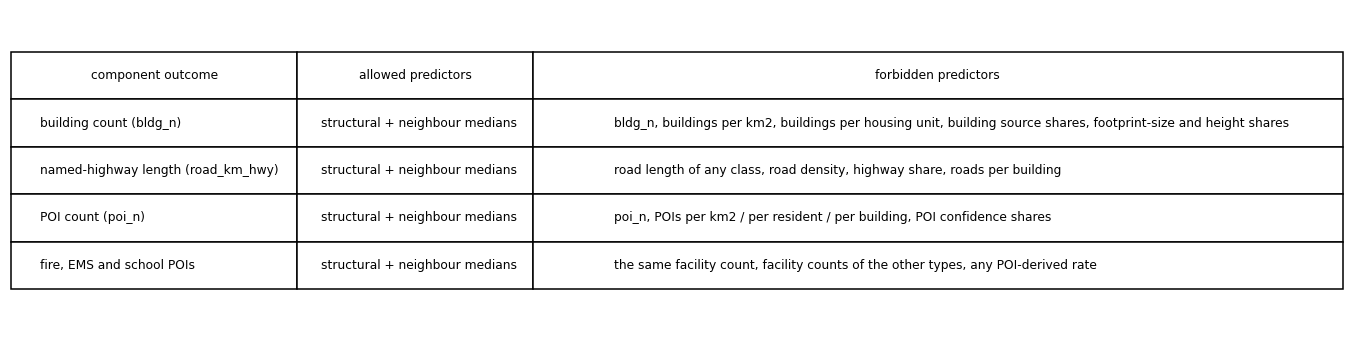

In [3]:
wl = pd.DataFrame([
 ("building count (bldg_n)", "structural + neighbour medians", "bldg_n, buildings per km2, buildings per housing unit, building source shares, footprint-size and height shares"),
 ("named-highway length (road_km_hwy)", "structural + neighbour medians", "road length of any class, road density, highway share, roads per building"),
 ("POI count (poi_n)", "structural + neighbour medians", "poi_n, POIs per km2 / per resident / per building, POI confidence shares"),
 ("fire, EMS and school POIs", "structural + neighbour medians", "the same facility count, facility counts of the other types, any POI-derived rate")],
 columns=["component outcome", "allowed predictors", "forbidden predictors"])
print(wl.to_string(index=False))
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off"); tb = ax.table(cellText=wl.values, colLabels=wl.columns, loc="center", cellLoc="left"); tb.auto_set_font_size(False); tb.set_fontsize(8); tb.scale(1, 2.2); tb.auto_set_column_width([0, 1, 2]); plt.tight_layout(); plt.show()

**Takeaway:** each component model gets only structural and neighbour-median predictors. Anything computed from its own outcome (counts, densities, shares, ratios) is forbidden, so the building model cannot use buildings per km2 or buildings per housing unit, and the POI models cannot use any POI-derived rate. Cross-component ratios are kept for the later inconsistency stage only.

## 3. Structural features and neighbour medians
Neighbours are the 6 nearest tract centroids within the same region (tract polygons are not on disk, so centroids stand in for adjacency).

                  skew raw  skew log1p  missing %
land_km2              8.54        1.34       0.00
housing_units         1.94       -6.06       0.00
pop_total             1.68       -6.14       0.00
hu_per_km2            4.00       -1.04       0.02
pop_density           3.46       -1.18       0.02
nb_land_km2           9.19        1.59       0.00
nb_housing_units      0.73       -2.43       0.00
nb_pop_density        1.62       -1.52       0.00
nb_hu_per_km2         2.82       -1.39       0.00


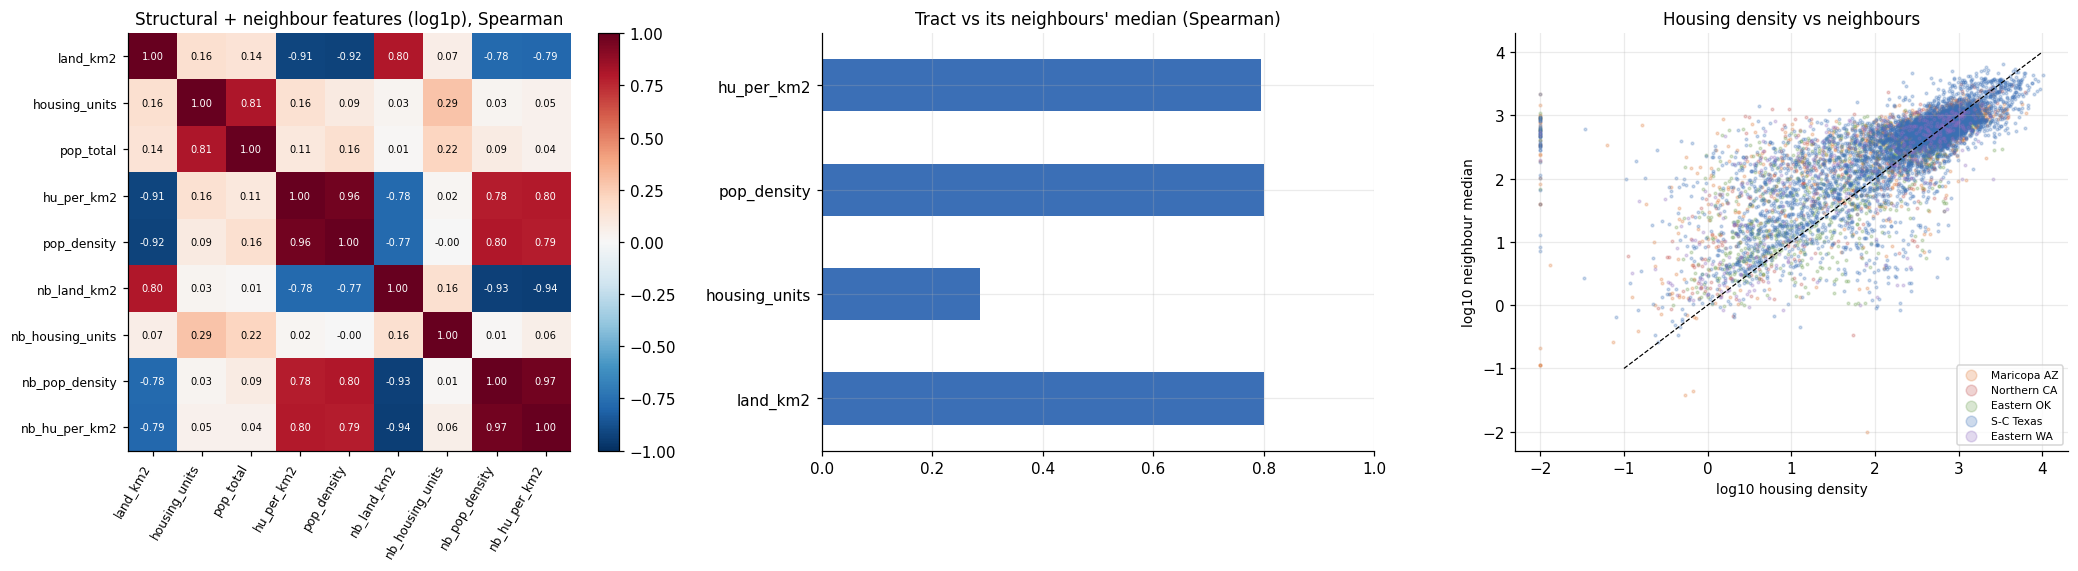

Spearman own vs neighbour median: {'land_km2': 0.8, 'housing_units': 0.29, 'pop_density': 0.8, 'hu_per_km2': 0.8}


In [4]:
from sklearn.neighbors import NearestNeighbors
lat0 = np.deg2rad(df.INTPTLAT.mean()); df["x_km"] = df.INTPTLON * 111.32 * np.cos(np.deg2rad(df.INTPTLAT)); df["y_km"] = df.INTPTLAT * 110.57
for c in ["land_km2", "housing_units", "pop_density", "hu_per_km2"]: df["nb_" + c] = np.nan
base = df.copy()
for r in REG:
    m = (df.region == r).values; xy = df.loc[m, ["x_km", "y_km"]].values; nn = NearestNeighbors(n_neighbors=7).fit(xy); idx = nn.kneighbors(xy, return_distance=False)[:, 1:]
    for c in ["land_km2", "housing_units", "pop_density", "hu_per_km2"]: v = df.loc[m, c].values; df.loc[m, "nb_" + c] = np.nanmedian(v[idx], axis=1)
S = ["land_km2", "housing_units", "pop_total", "hu_per_km2", "pop_density"]; NB = ["nb_land_km2", "nb_housing_units", "nb_pop_density", "nb_hu_per_km2"]
sk = pd.DataFrame({"skew raw": df[S + NB].apply(lambda s: stats.skew(s.dropna())), "skew log1p": np.log1p(df[S + NB].clip(lower=0)).apply(lambda s: stats.skew(s.dropna())), "missing %": df[S + NB].isna().mean() * 100}); print(sk.round(2).to_string())
own = pd.Series({c: stats.spearmanr(df[c], df["nb_" + c], nan_policy="omit")[0] for c in ["land_km2", "housing_units", "pop_density", "hu_per_km2"]})
cm = np.log1p(df[S + NB].clip(lower=0)).corr(method="spearman")
fig, ax = plt.subplots(1, 3, figsize=(19, 5.3)); plt.colorbar(heat(ax[0], cm, fs=6.5, rot=60), ax=ax[0]); ax[0].set_title("Structural + neighbour features (log1p), Spearman")
own.plot.barh(ax=ax[1], color="#3b6fb6"); ax[1].set_title("Tract vs its neighbours' median (Spearman)"); ax[1].set_xlim(0, 1)
for r in REG: d_ = df[df.region == r]; ax[2].scatter(np.log10(d_.hu_per_km2.clip(lower=.01)), np.log10(d_.nb_hu_per_km2.clip(lower=.01)), s=3, alpha=.25, color=COL[r], label=NAME[r])
ax[2].plot([-1, 4], [-1, 4], "k--", lw=.8); ax[2].set(xlabel="log10 housing density", ylabel="log10 neighbour median", title="Housing density vs neighbours"); ax[2].legend(markerscale=4, fontsize=7)
plt.tight_layout(); plt.show(); print("Spearman own vs neighbour median:", own.round(2).to_dict())

**Takeaway:** raw area is very skewed (skew 8.5, 1.3 after log1p), so the expectation model needs logs or a count model with a log link. A tract's land area, housing density and population density agree with its neighbours' medians (Spearman 0.80), whereas housing units agree much less (0.29), consistent with tracts being drawn around similar populations. The neighbour medians therefore add context beyond the tract's own values, without using any outcome.

## 4. Provenance features: how concentrated are the building sources?
Shannon entropy and the Herfindahl-Hirschman index of each tract's building-source shares. Low entropy / high HHI means the tract depends on one upstream source.

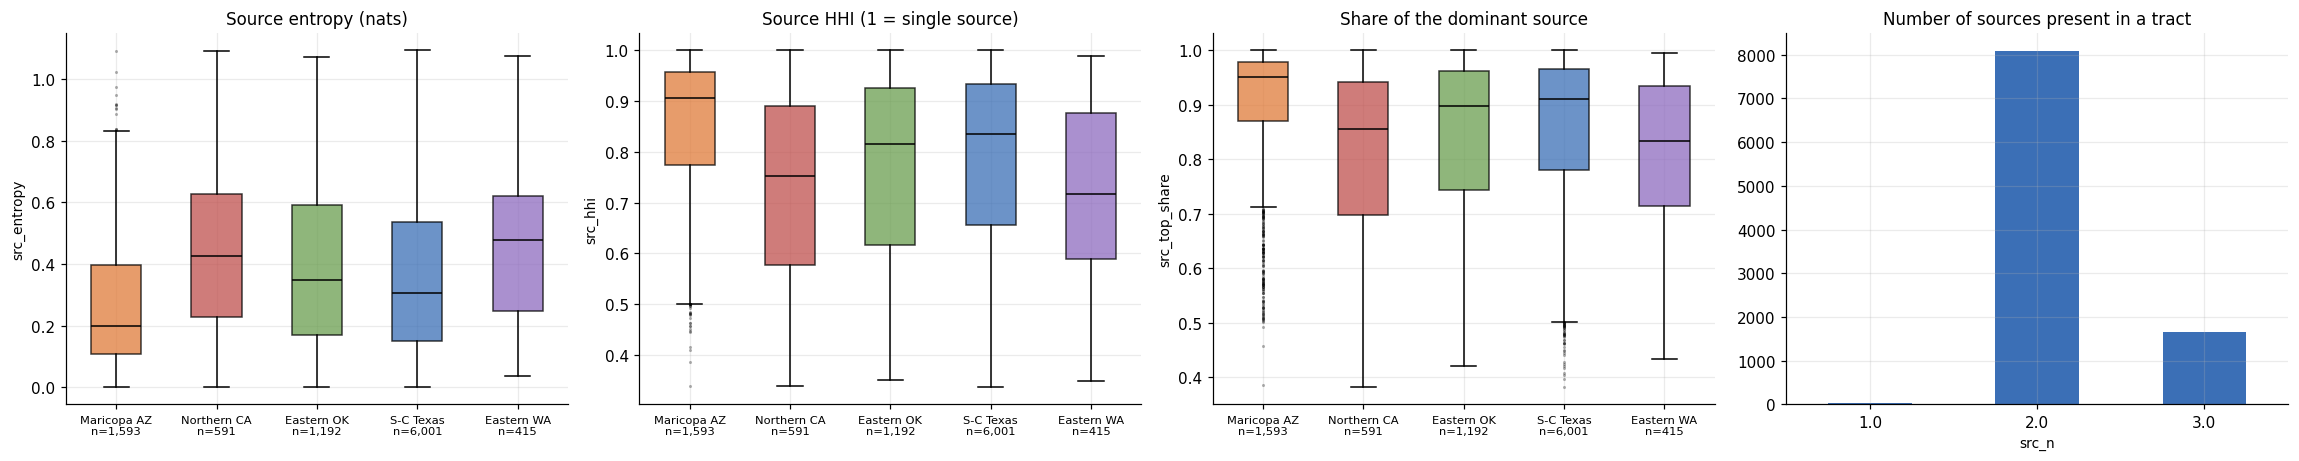

                  src_entropy  src_hhi  src_top_share
region                                               
maricopa-az              0.20     0.91           0.95
northern-ca              0.42     0.75           0.85
eastern-ok               0.35     0.81           0.90
south-central-tx         0.31     0.84           0.91
eastern-wa               0.48     0.72           0.83

tracts with a single source: 38 (0%) | dominant source share > 0.9: 54%
Spearman entropy vs structural: {'hu_per_km2': np.float64(-0.14), 'pop_density': np.float64(-0.14), 'land_km2': np.float64(0.12)}
Spearman entropy vs share_msft: 0.12


In [5]:
src = ["bldg_n_osm", "bldg_n_msft", "bldg_n_esri", "bldg_n_google", "bldg_n_other"]; P = df[src].div(df.bldg_n.replace(0, np.nan), axis=0)
df["src_entropy"] = -xlogy(P, P).sum(axis=1).where(df.bldg_n > 0); df["src_hhi"] = (P ** 2).sum(axis=1).where(df.bldg_n > 0); df["src_n"] = (df[src] > 0).sum(axis=1).where(df.bldg_n > 0); df["src_top_share"] = P.max(axis=1)
df["share_google"] = df.bldg_n_google / df.bldg_n.replace(0, np.nan); df["share_esri"] = df.bldg_n_esri / df.bldg_n.replace(0, np.nan)
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3)); box_by_region(ax[0], "src_entropy", title="Source entropy (nats)"); box_by_region(ax[1], "src_hhi", title="Source HHI (1 = single source)"); box_by_region(ax[2], "src_top_share", title="Share of the dominant source")
df.src_n.value_counts().sort_index().plot.bar(ax=ax[3], color="#3b6fb6", rot=0); ax[3].set_title("Number of sources present in a tract")
plt.tight_layout(); plt.show(); print(df.groupby("region")[["src_entropy", "src_hhi", "src_top_share"]].median().reindex(REG).round(2).to_string()); print("\ntracts with a single source:", int((df.src_n == 1).sum()), f"({(df.src_n == 1).mean():.0%})", "| dominant source share > 0.9:", f"{(df.src_top_share > .9).mean():.0%}")
print("Spearman entropy vs structural:", {c: round(stats.spearmanr(df.src_entropy, df[c], nan_policy="omit")[0], 2) for c in ["hu_per_km2", "pop_density", "land_km2"]})
print("Spearman entropy vs share_msft:", round(stats.spearmanr(df.src_entropy, df.share_msft, nan_policy="omit")[0], 2))

**Takeaway:** building sources are concentrated: the dominant source supplies more than 90% of buildings in 54% of tracts, and only 38 tracts have a single source. Median source entropy is lowest in Maricopa (0.20) and highest in Eastern WA (0.48), and it is only weakly related to density or area (|Spearman| 0.14 or less), so it carries information that the structural features do not.

## 5. Cross-component indicators (for the inconsistency stage only)
Ratios between components, used to flag tracts whose themes disagree. They are never predictors of the expectation model.

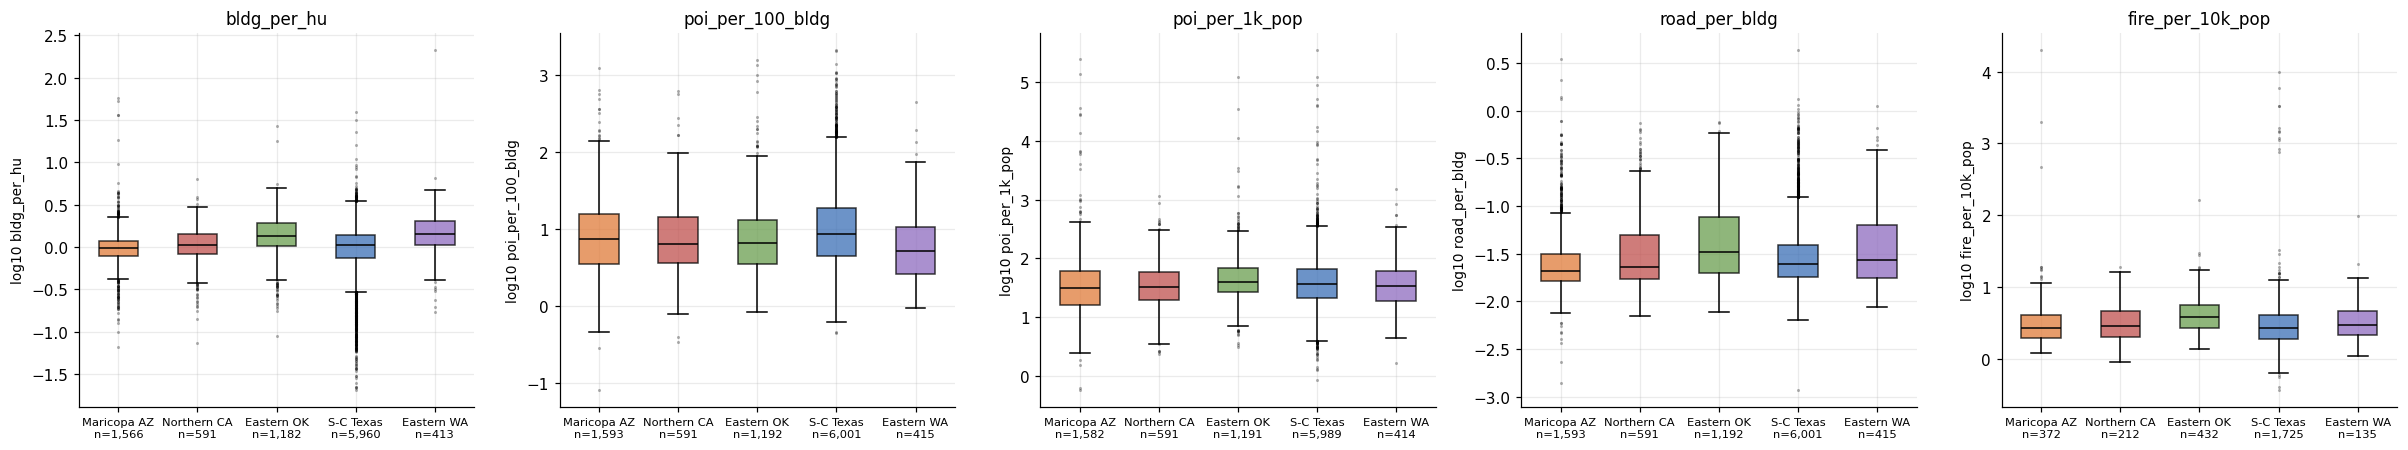

                  bldg_per_hu  poi_per_100_bldg  poi_per_1k_pop  road_per_bldg  fire_per_10k_pop
bldg_per_hu              1.00             -0.54           -0.06           0.37              0.26
poi_per_100_bldg        -0.54              1.00            0.79          -0.04             -0.02
poi_per_1k_pop          -0.06              0.79            1.00           0.25              0.19
road_per_bldg            0.37             -0.04            0.25           1.00              0.31
fire_per_10k_pop         0.26             -0.02            0.19           0.31              1.00

share of tracts with a zero fire rate: 0.7 | missing: {'bldg_per_hu': 0.008, 'poi_per_100_bldg': 0.0, 'poi_per_1k_pop': 0.003, 'road_per_bldg': 0.0, 'fire_per_10k_pop': 0.003}


In [6]:
df["road_per_bldg"] = df.road_km_all / df.bldg_n.replace(0, np.nan); df["fire_per_10k_pop"] = df.poi_n_fire * 1e4 / df.pop_total.replace(0, np.nan)
X = ["bldg_per_hu", "poi_per_100_bldg", "poi_per_1k_pop", "road_per_bldg", "fire_per_10k_pop"]
fig, ax = plt.subplots(1, 5, figsize=(22, 4.2))
for a, c in zip(ax, X): box_by_region(a, c, log=True, title=c)
plt.tight_layout(); plt.show()
cm = df[X].replace(np.inf, np.nan).corr(method="spearman"); print(cm.round(2).to_string()); print("\nshare of tracts with a zero fire rate:", round((df.fire_per_10k_pop == 0).mean(), 2), "| missing:", df[X].isna().mean().round(3).to_dict())

**Takeaway:** the ratios are partly redundant: POIs per 100 buildings and per 1,000 residents correlate at 0.79, and buildings per home moves against POIs per building (-0.54). The fire rate is zero in 70% of tracts, so it can only act as a flag, not a continuous measure. These stay in the inconsistency stage, never in the expectation model.

## 6. Do the regions look alike on the allowed features?
Using only structural, neighbour and provenance features (no hazards, no strata).

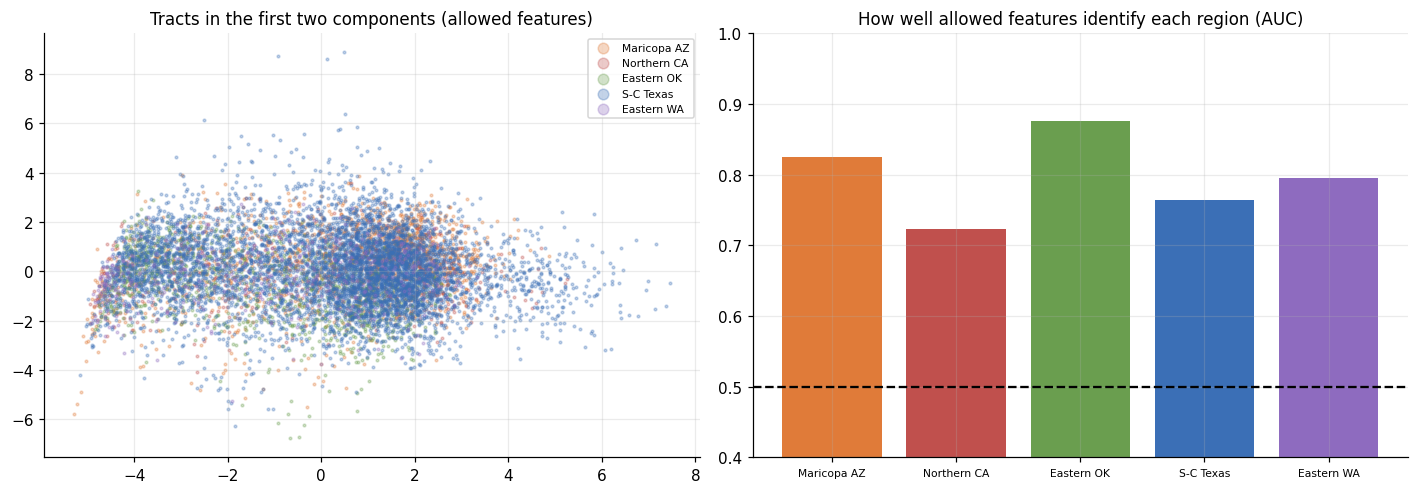

AUC: {'Maricopa AZ': 0.825, 'Northern CA': 0.723, 'Eastern OK': 0.875, 'S-C Texas': 0.764, 'Eastern WA': 0.796} | accuracy 0.668 (61% from always guessing Texas)


In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PowerTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
allowed = S + NB + ["src_entropy", "src_hhi"]; Z = pd.DataFrame(PowerTransformer("yeo-johnson").fit_transform(df[allowed].fillna(df[allowed].median())), columns=allowed)
pr = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, max_iter=120, random_state=0), Z, df.region, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba"); cls = sorted(df.region.unique())
auc = {r: roc_auc_score(df.region == r, pr[:, cls.index(r)]) for r in REG}; acc = (np.array(cls)[pr.argmax(1)] == df.region.values).mean(); P2 = PCA(2).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for r in REG: m = (df.region == r).values; ax[0].scatter(P2[m, 0], P2[m, 1], s=3, alpha=.3, color=COL[r], label=NAME[r])
ax[0].legend(markerscale=4, fontsize=7); ax[0].set_title("Tracts in the first two components (allowed features)"); ax[1].bar([NAME[r] for r in REG], [auc[r] for r in REG], color=[COL[r] for r in REG]); ax[1].axhline(.5, color="k", ls="--"); ax[1].set_ylim(.4, 1); ax[1].set_title("How well allowed features identify each region (AUC)"); ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show(); print("AUC:", {NAME[r]: round(v, 3) for r, v in auc.items()}, "| accuracy", round(acc, 3), "(61% from always guessing Texas)")

**Takeaway:** even on allowed features alone the regions are only partly separable (AUC 0.72 for Northern CA to 0.88 for Eastern OK, accuracy 0.67 against 0.61 for always guessing Texas). That is far lower than the 0.997 seen when hazards and strata were included, so the allowed feature set is much less region-specific, which should help transfer across regions.

## 7. Frozen validation folds
Spatial blocks: a 40 km grid on projected centroids, blocks assigned to five folds that balance tract counts. Leave-one-region-out is added on top. Folds are created once, before any modelling, and saved.

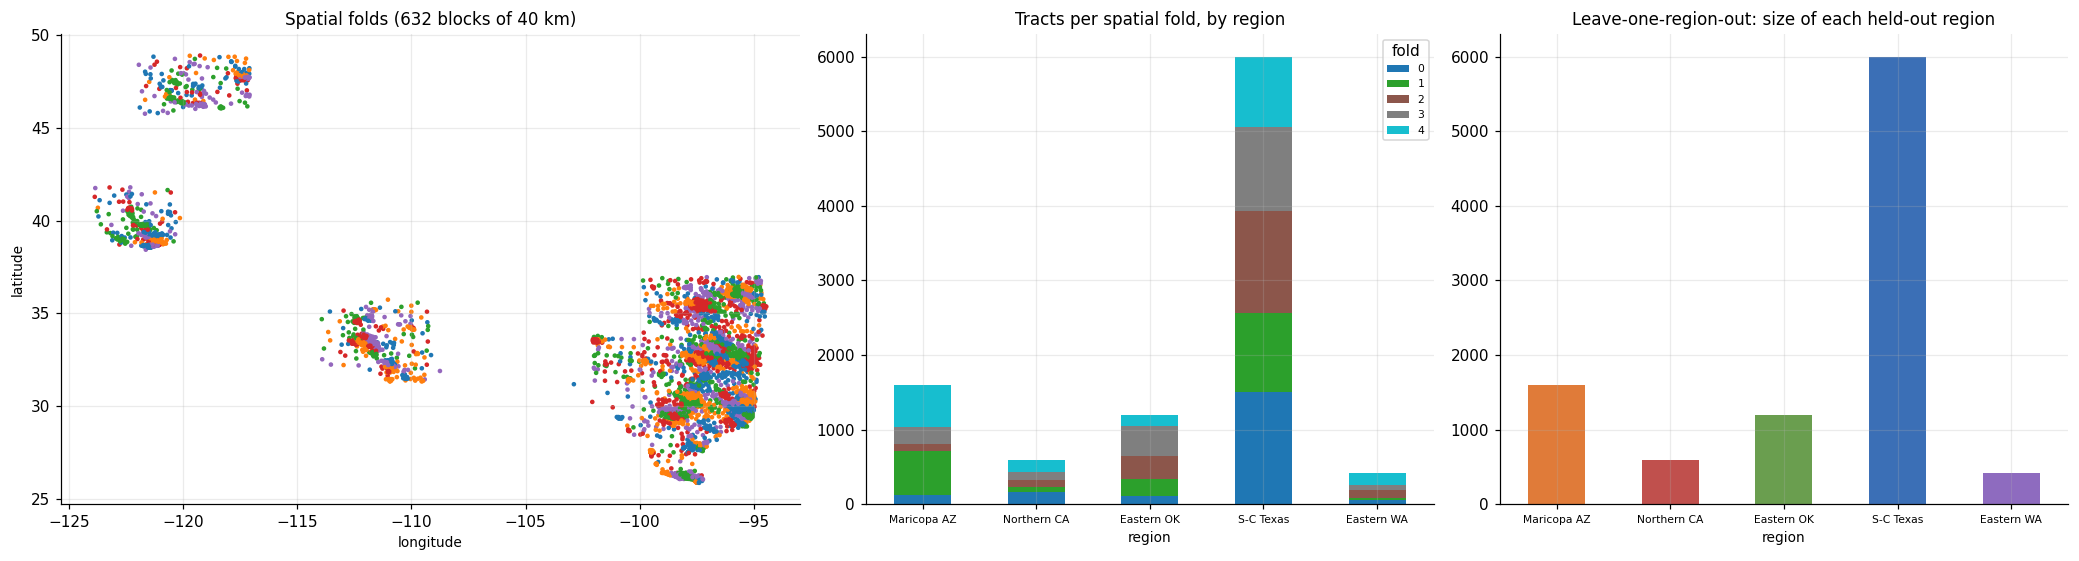

fold sizes: {0: 1959, 1: 1959, 2: 1959, 3: 1959, 4: 1958}
blocks per region: {'maricopa-az': 99, 'northern-ca': 62, 'eastern-ok': 111, 'south-central-tx': 285, 'eastern-wa': 75}
largest block: 662 tracts ( south-central-tx_-231_82 )
tracts per fold per region:
spatial_fold         0     1     2     3    4
region                                       
maricopa-az        123   589    89   240  552
northern-ca        162    66    93   114  156
eastern-ok         109   223   309   404  147
south-central-tx  1509  1049  1372  1134  939
eastern-wa          56    32    96    67  164


In [8]:
bs = 40.0; df["block"] = df.region + "_" + (df.x_km // bs).astype(int).astype(str) + "_" + (df.y_km // bs).astype(int).astype(str)
bc = df.groupby("block").size().sort_values(ascending=False); load = np.zeros(5); asg = {}
for b, n in bc.items(): k = int(load.argmin()); asg[b] = k; load[k] += n
df["spatial_fold"] = df.block.map(asg); rng = np.random.default_rng(42); df["random_fold"] = rng.permutation(len(df)) % 5
ct = pd.crosstab(df.region, df.spatial_fold).reindex(REG)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
sc = ax[0].scatter(df.INTPTLON, df.INTPTLAT, c=df.spatial_fold, s=4, cmap="tab10", vmin=0, vmax=9); ax[0].set_title(f"Spatial folds ({df.block.nunique()} blocks of {bs:.0f} km)"); ax[0].set(xlabel="longitude", ylabel="latitude")
ct.plot.bar(stacked=True, ax=ax[1], rot=0, colormap="tab10"); ax[1].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[1].set_title("Tracts per spatial fold, by region"); ax[1].legend(title="fold", fontsize=7)
(df.groupby("region").size().reindex(REG)).plot.bar(ax=ax[2], rot=0, color=[COL[r] for r in REG]); ax[2].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[2].set_title("Leave-one-region-out: size of each held-out region")
plt.tight_layout(); plt.show(); print("fold sizes:", df.spatial_fold.value_counts().sort_index().to_dict()); print("blocks per region:", df.groupby("region").block.nunique().reindex(REG).to_dict()); print("largest block:", int(bc.iloc[0]), "tracts (", bc.index[0], ")")
print("tracts per fold per region:"); print(ct.to_string())

**Takeaway:** five spatial folds hold 1,958-1,959 tracts each, built from 40 km blocks (632 blocks in total). Texas dominates every fold (939-1,509 tracts) and its largest block holds 662 tracts, while Maricopa is uneven (89-589 per fold), so results must be reported per region and macro-averaged, with leave-one-region-out as the harder test. Random folds are saved only to show how optimistic they are.

## 8. Save model inputs and audit strata separately
Two files, so a modelling notebook cannot touch audit variables by accident.

In [9]:
inputs = ["GEOID", "region", "competition", "random_fold", "spatial_fold", "block"] + S + NB + ["bldg_n", "road_km_hwy", "road_km_all", "poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school"] + ["src_entropy", "src_hhi", "src_n", "src_top_share"] + X
audit = ["GEOID", "region", "ur_class", "rural", "ruca_primary", "rucc_2023", "tribal", "tribal_pct", "svi_overall", "svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport", "cvi_overall", "cvi_baseline", "cvi_climate",
         "usdm_summer_dsci", "usdm_winter_dsci", "pmdi_mean", "spi12_mean", "usfs_WHP_mean", "epht_heat_days_summer", "gehe_wbgt28_days_mean", "hwd_maxtemp_mean", "mtbs_wildfire_ever", "fod_fires"]
OUT.mkdir(exist_ok=True); df[inputs].to_parquet(OUT / "model_inputs.parquet", index=False); df[audit].to_parquet(OUT / "audit_strata.parquet", index=False); reg.to_csv(OUT / "feature_registry.csv", index=False)
mi = pd.read_parquet(OUT / "model_inputs.parquet"); au = pd.read_parquet(OUT / "audit_strata.parquet")
print("model_inputs:", mi.shape, "| audit_strata:", au.shape, "| overlap of columns (should be only keys):", sorted(set(mi.columns) & set(au.columns)))
print("audit-only columns inside model_inputs:", [c for c in mi.columns if c in roles["audit-only (strata)"]], "| excluded columns inside:", [c for c in mi.columns if c in roles["excluded (reference-like building/housing/population counts)"]])
print("competition tracts:", int(mi.competition.sum()), "| academic transfer set (Eastern WA):", int((~mi.competition).sum()))

model_inputs: (9794, 31) | audit_strata: (9794, 26) | overlap of columns (should be only keys): ['GEOID', 'region']
audit-only columns inside model_inputs: [] | excluded columns inside: []
competition tracts: 9379 | academic transfer set (Eastern WA): 415


**Takeaway:** model_inputs.parquet (9,794 x 31) and audit_strata.parquet (9,794 x 26) share only the keys GEOID and region, and no audit-only or excluded column appears in the model inputs. 9,379 tracts are flagged as competition tracts and the 415 Eastern WA tracts as the academic transfer set. The feature registry is saved alongside as feature_registry.csv.